In [215]:
# Import necessary libraries (same as the professor's FFNN example)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, RobustScaler
from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader, TensorDataset

import time

# Set random seed for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# TASK 1

In [216]:
# ------------------------------------------------------------------------------
# TASK 1
# ------------------------------------------------------------------------------

# ------------------------------------------------------------------------------
# LOAD DATASET
# ------------------------------------------------------------------------------
data = pd.read_csv("dataset_lab_1.csv")
data.columns = data.columns.str.strip()   # remove possible leading spaces in column names

print("Number of rows:", len(data))
data.head()

Number of rows: 31507


,Flow Duration,Flow IAT Mean,Fwd PSH Flags,Bwd Packet Length Mean,Bwd Packet Length Max,Flow Bytes/s,Down/Up Ratio,SYN Flag Count,Fwd Packet Length Mean,Fwd IAT Std,Packet Length Mean,Fwd Packet Length Max,Subflow Fwd Packets,Flow Packets/s,Total Fwd Packets,Destination Port,Label
0,303376,30337.600000,0,749.4,1448,12743.263,0,0,19.833334,98776.15,322.16666,119,6,36.258636,6,443,Benign
1,117,117.000000,0,0.0,0,0.000,1,0,0.000000,0.00,0.00000,0,1,17094.018000,1,52631,Benign
2,142,142.000000,0,0.0,0,84507.040,0,0,6.000000,0.00,6.00000,6,2,14084.507000,2,80,Benign
3,191,63.666668,0,52.0,52,921465.940,1,0,36.000000,0.00,42.40000,36,2,20942.408000,2,53,Benign
4,4,4.000000,0,0.0,0,3000000.000,0,0,6.000000,0.00,6.00000,6,2,500000.000000,2,49467,Benign


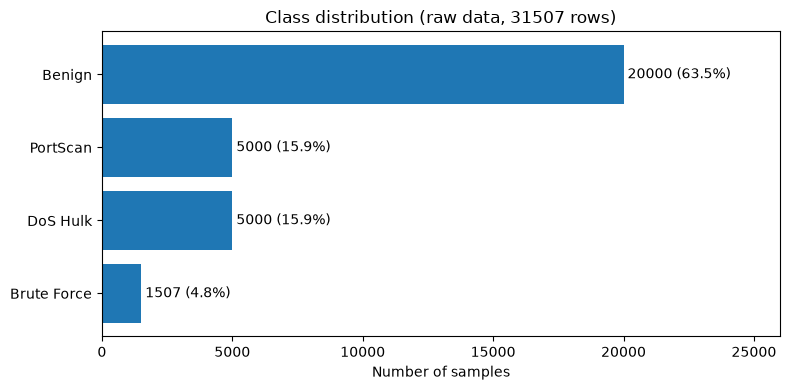

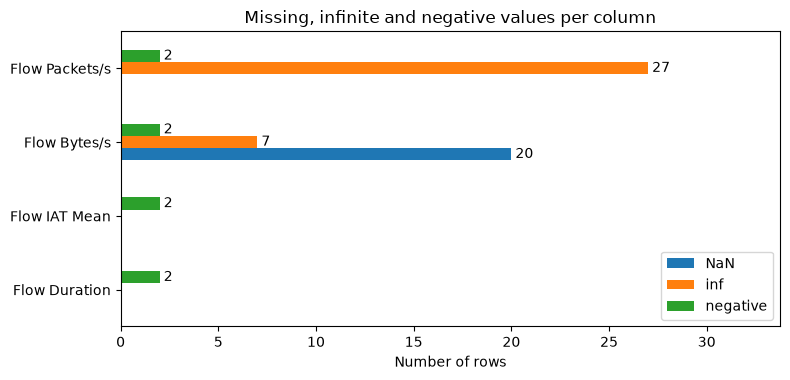

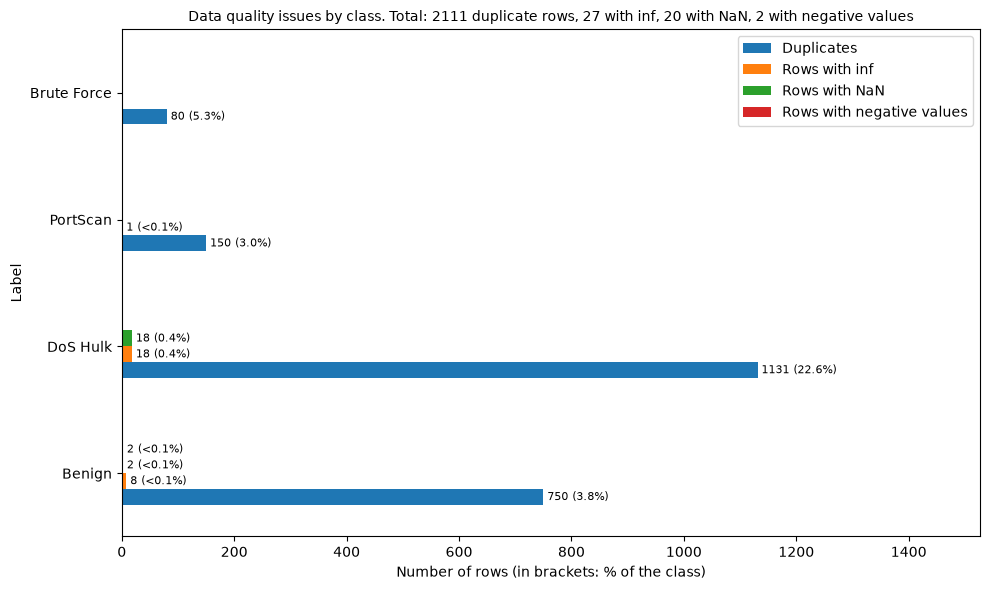

Constant columns: none
Pairs of columns with the same value in >99% of rows: {'Fwd PSH Flags = SYN Flag Count': '100.00%', 'Subflow Fwd Packets = Total Fwd Packets': '100.00%'}


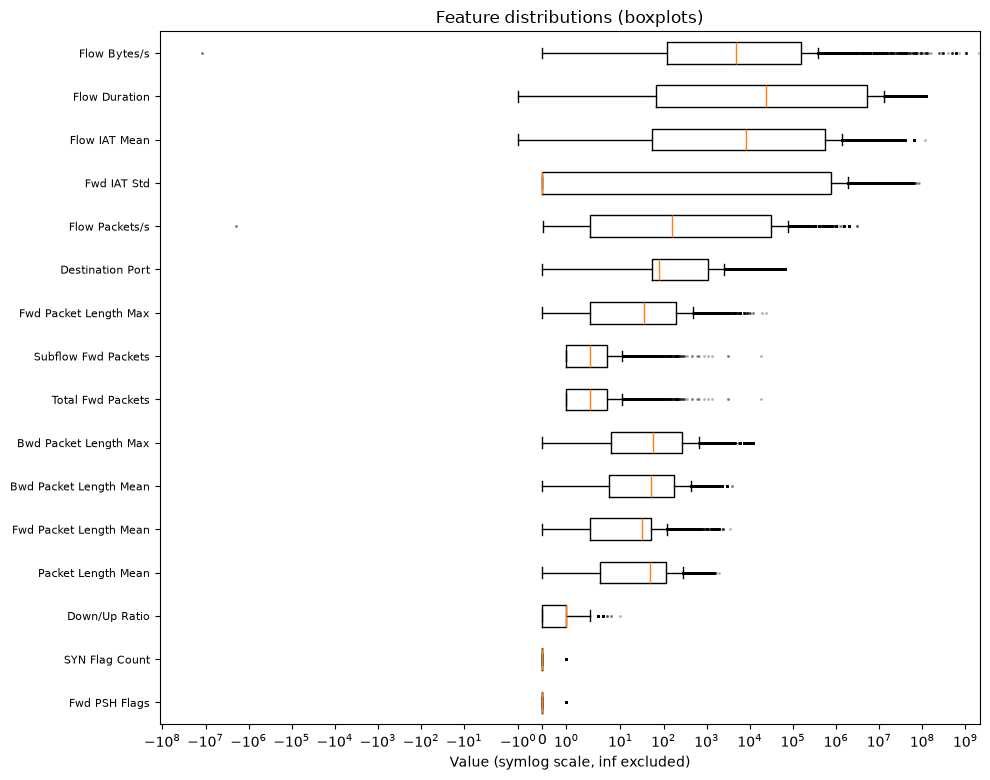

In [217]:
# ------------------------------------------------------------------------------
# INSPECTION
# ------------------------------------------------------------------------------

# Classes and balance
counts_raw = data["Label"].value_counts()   # saved for the raw vs cleaned comparison
counts = counts_raw.sort_values()
perc = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(counts.index, counts.values)
for i, (c, p) in enumerate(zip(counts.values, perc.values)):
    ax.text(c, i, f" {c} ({p:.1f}%)", va="center")
ax.set_xlim(0, counts.max() * 1.3)   # room for the labels on the longest bar
ax.set_xlabel("Number of samples")
ax.set_title(f"Class distribution (raw data, {len(data)} rows)")
plt.tight_layout()
plt.show()
plt.close()

# Features only; num_box = same values with inf turned into NaN (for statistics and plots)
num = data.drop(columns=["Label"])
num_box = num.replace([np.inf, -np.inf], np.nan)

# Missing, infinite and negative values per column
# (all features are counts, sizes, durations, rates or ports: negative values are implausible)
bad_cols = pd.DataFrame({"NaN": num.isna().sum(),
                         "inf": np.isinf(num).sum(),
                         "negative": (num_box < 0).sum()})
bad_cols = bad_cols[(bad_cols > 0).any(axis=1)]

if len(bad_cols) > 0:
    ax = bad_cols.plot.barh(figsize=(8, 0.6 * len(bad_cols) + 1.5))
    for cont in ax.containers:   # exact numbers on the bars (0 hidden)
        ax.bar_label(cont, labels=[f" {int(v)}" if v > 0 else "" for v in cont.datavalues])
    ax.set_xlim(0, bad_cols.values.max() * 1.25)
    ax.set_xlabel("Number of rows")
    ax.set_title("Missing, infinite and negative values per column")
    plt.tight_layout()
    plt.show()
    plt.close()
else:
    print("No NaN, inf or negative values found")

# Data quality issues by class: number of rows and % of each class in one plot
dup_mask = data.duplicated()
inf_mask = np.isinf(num).any(axis=1)
nan_mask = data.isna().any(axis=1)
neg_mask = (num_box < 0).any(axis=1)

issues = pd.DataFrame({
    "Duplicates": data[dup_mask]["Label"].value_counts(),
    "Rows with inf": data[inf_mask]["Label"].value_counts(),
    "Rows with NaN": data[nan_mask]["Label"].value_counts(),
    "Rows with negative values": data[neg_mask]["Label"].value_counts(),
}).reindex(counts_raw.index).fillna(0).astype(int)
issues_perc = issues.div(counts_raw, axis=0) * 100

ax = issues.plot.barh(figsize=(10, 6))
for cont, col in zip(ax.containers, issues.columns):
    labels = []
    for n, p in zip(issues[col], issues_perc[col]):
        if n == 0:
            labels.append("")
        elif p < 0.1:
            labels.append(f" {n} (<0.1%)")
        else:
            labels.append(f" {n} ({p:.1f}%)")
    ax.bar_label(cont, labels=labels, fontsize=8)
ax.set_xlim(0, issues.values.max() * 1.35)   # room for the labels
ax.set_xlabel("Number of rows (in brackets: % of the class)")
ax.set_title(f"Data quality issues by class. Total: {dup_mask.sum()} duplicate rows, "
             f"{inf_mask.sum()} with inf, {nan_mask.sum()} with NaN, {neg_mask.sum()} with negative values",
             fontsize=10)
plt.tight_layout()
plt.show()
plt.close()

# Degenerate features: constant columns and (almost) identical pairs of columns
const_cols = num_box.columns[num_box.nunique() <= 1].tolist()
cols = num_box.columns
same_pairs = {f"{a} = {b}": (num_box[a] == num_box[b]).mean() * 100
              for i, a in enumerate(cols) for b in cols[i + 1:]
              if (num_box[a] == num_box[b]).mean() > 0.99}
print("Constant columns:", const_cols if const_cols else "none")
print("Pairs of columns with the same value in >99% of rows:",
      {k: f"{v:.2f}%" for k, v in same_pairs.items()} if same_pairs else "none")

# Feature distributions: boxplots on a shared symlog axis (inf excluded)
order = num_box.max().sort_values().index   # most extreme features at the top

fig, ax = plt.subplots(figsize=(10, 0.4 * len(order) + 1.5))
ax.boxplot([num_box[c].dropna() for c in order], orientation="horizontal",
           flierprops=dict(marker=".", markersize=2, alpha=0.3))
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order, fontsize=8)
ax.set_xscale("symlog")   # log scale that also handles 0 and negative values
ax.set_xlabel("Value (symlog scale, inf excluded)")
ax.set_title("Feature distributions (boxplots)")
plt.tight_layout()
plt.show()
plt.close()

Rows before cleaning:              31507
Removed duplicate rows:            2111
Removed rows with inf or NaN:      10 (10 with inf, 3 with NaN; a row can have both)
Removed rows with negative values: 2
Rows after cleaning:               29384


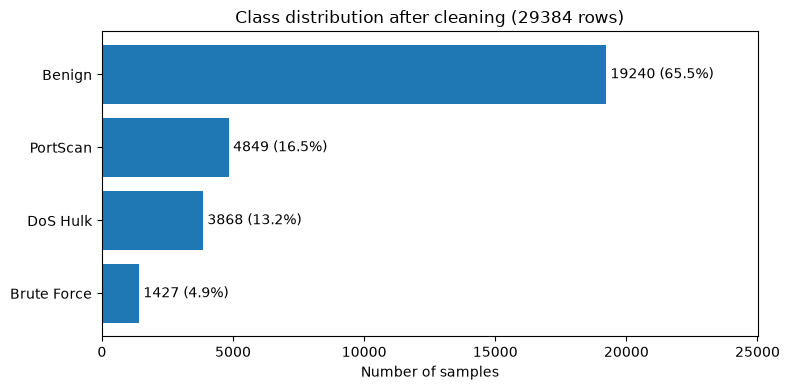

In [218]:
# ------------------------------------------------------------------------------
# PREPROCESSING
# ------------------------------------------------------------------------------
n_start = len(data)

# Remove duplicates
data = data.drop_duplicates()
n_dup = n_start - len(data)

# Remove rows with inf or NaN (counted on the rows left after removing duplicates)
features = data.drop(columns=["Label"])
inf_rows = np.isinf(features).any(axis=1)
nan_rows = features.isna().any(axis=1)
data = data.replace([np.inf, -np.inf], np.nan).dropna()

# Remove rows with implausible negative values (durations, rates, sizes, counts, ports cannot be < 0)
neg_rows = (data.drop(columns=["Label"]) < 0).any(axis=1)
data = data[~neg_rows]

print(f"Rows before cleaning:              {n_start}")
print(f"Removed duplicate rows:            {n_dup}")
print(f"Removed rows with inf or NaN:      {(inf_rows | nan_rows).sum()} "
      f"({inf_rows.sum()} with inf, {nan_rows.sum()} with NaN; a row can have both)")
print(f"Removed rows with negative values: {neg_rows.sum()}")
print(f"Rows after cleaning:               {len(data)}")

# Class balance plot after cleaning (before LabelEncoder, so class names are visible)
counts_clean = data["Label"].value_counts()
counts = counts_clean.sort_values()
perc = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(counts.index, counts.values)
for i, (c, p) in enumerate(zip(counts.values, perc.values)):
    ax.text(c, i, f" {c} ({p:.1f}%)", va="center")
ax.set_xlim(0, counts.max() * 1.3)   # room for the labels on the longest bar
ax.set_xlabel("Number of samples")
ax.set_title(f"Class distribution after cleaning ({len(data)} rows)")
plt.tight_layout()
plt.show()
plt.close()

# Encode labels
label_encoder = LabelEncoder()
data["Label"] = label_encoder.fit_transform(data["Label"])

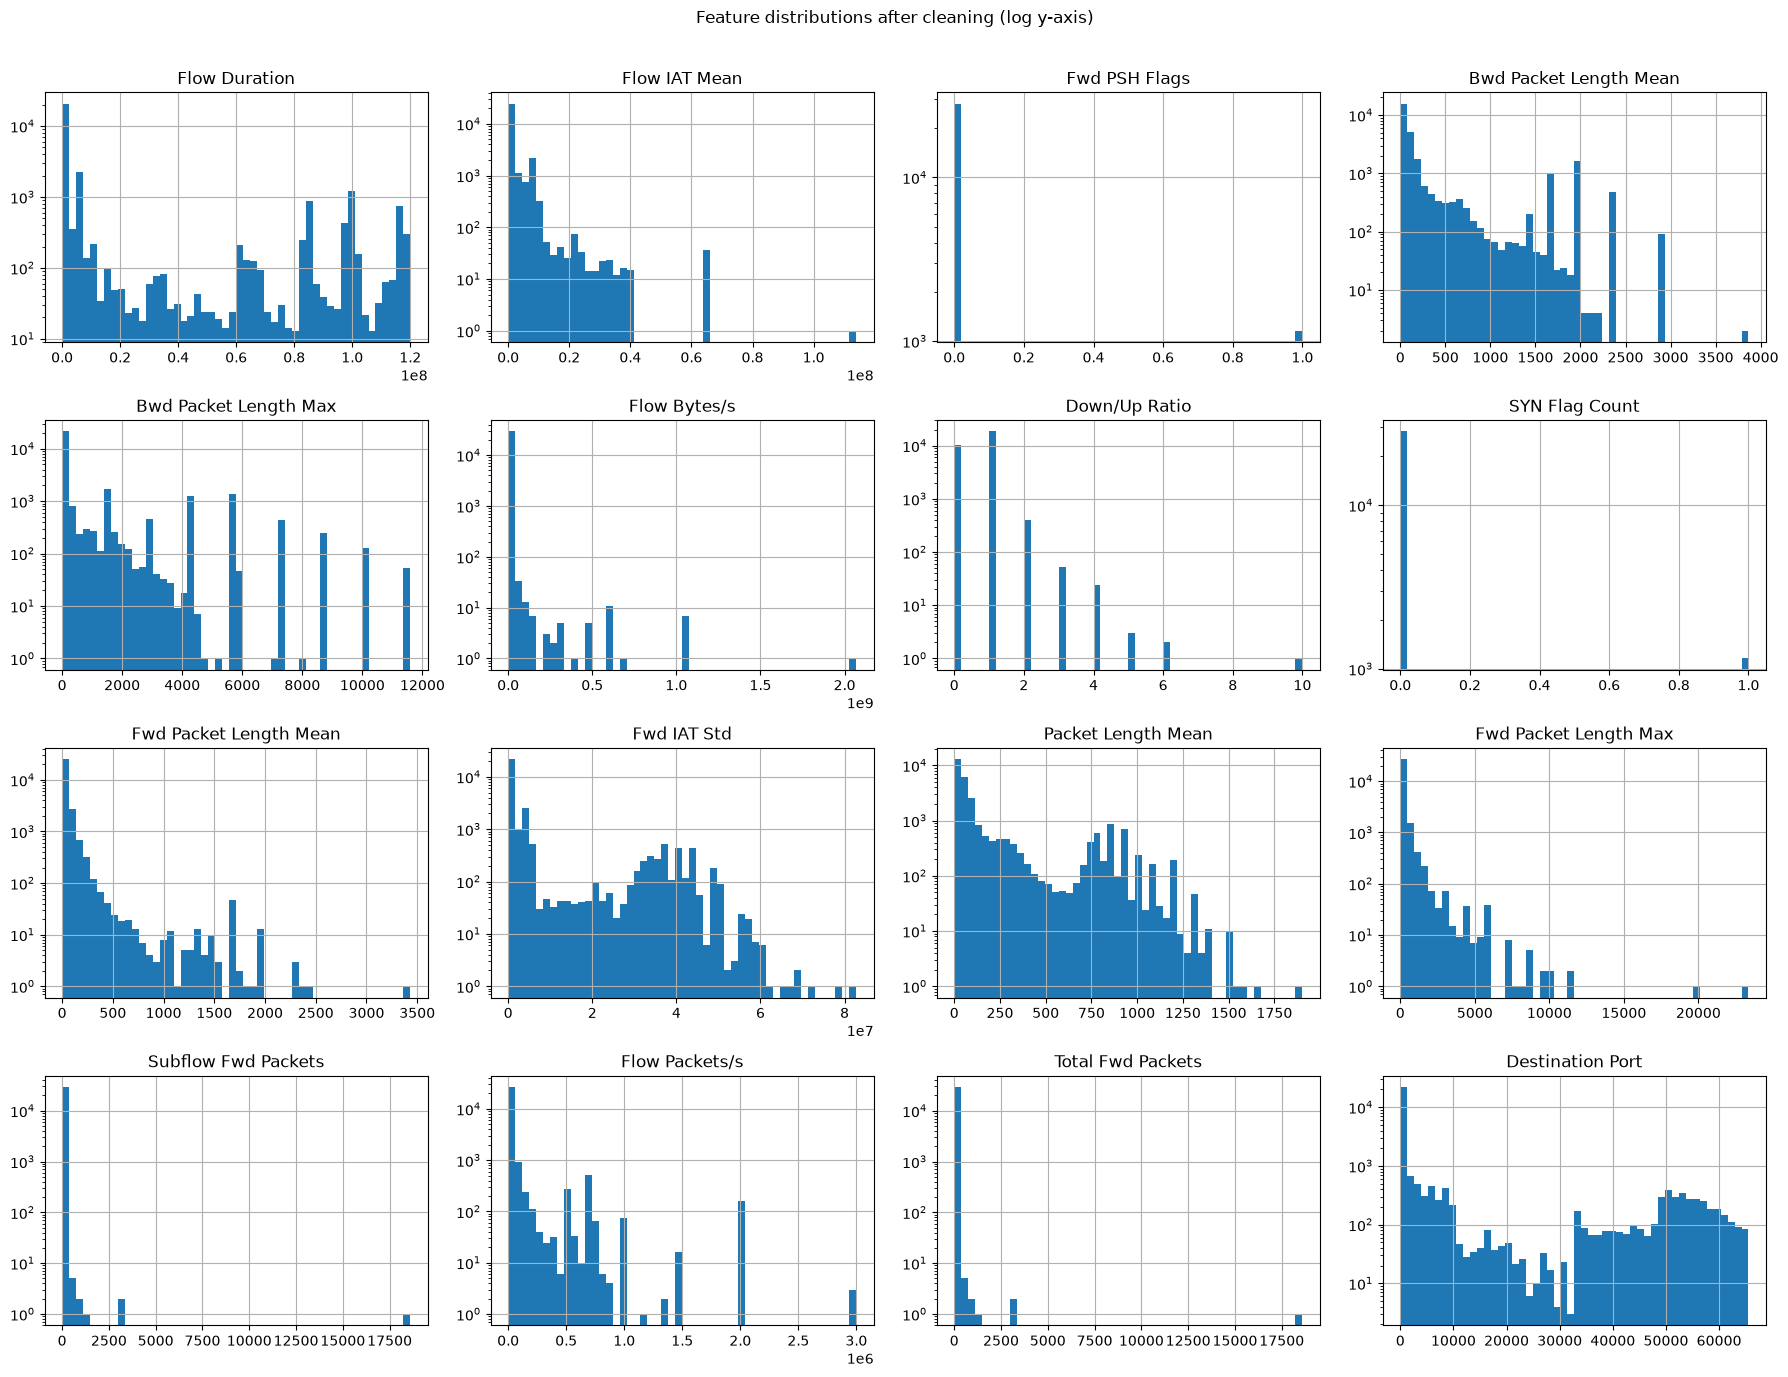

In [219]:
# ------------------------------------------------------------------------------
# DATA VISUALIZATION
# ------------------------------------------------------------------------------

# Too many features for a scatter plot: histograms of each feature instead
data.drop(columns=["Label"]).hist(bins=50, figsize=(18, 14), log=True)
plt.suptitle("Feature distributions after cleaning (log y-axis)")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()
plt.close()

In [220]:
# ------------------------------------------------------------------------------
# SPLITTING
# ------------------------------------------------------------------------------

feature_names = data.drop(columns=["Label"]).columns.tolist()
X = data[feature_names].values
y = data["Label"].values

# stratify=y keeps the same class proportions in every partition (imbalanced classes)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

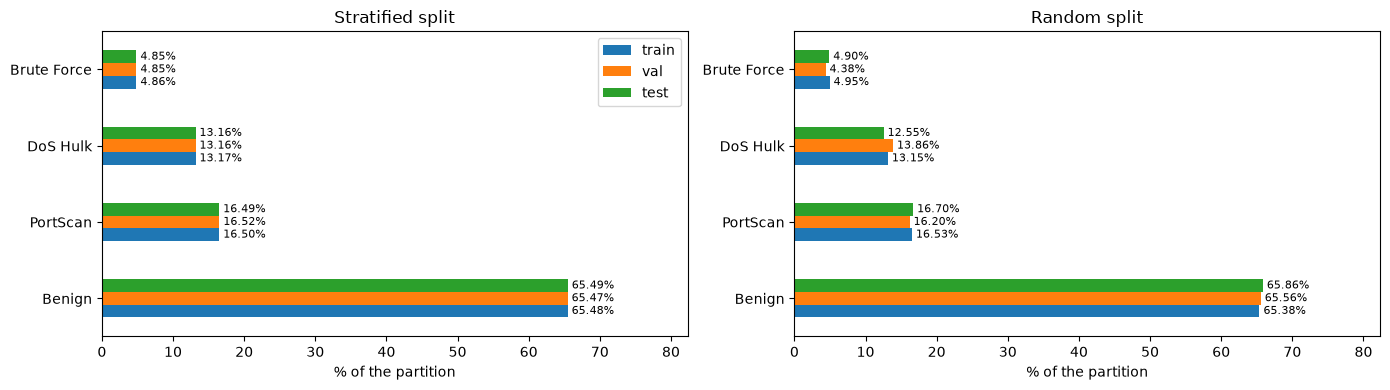

In [221]:
# ------------------------------------------------------------------------------
# STRATIFICATION CHECK: same split (same seed) with and without stratify
# ------------------------------------------------------------------------------
def split_proportions(stratified):
    y_tr, y_tmp = train_test_split(y, test_size=0.3, random_state=SEED,
                                   stratify=y if stratified else None)
    y_v, y_t = train_test_split(y_tmp, test_size=0.5, random_state=SEED,
                                stratify=y_tmp if stratified else None)
    return pd.DataFrame({
        name: pd.Series(label_encoder.inverse_transform(yy)).value_counts(normalize=True) * 100
        for name, yy in [("train", y_tr), ("val", y_v), ("test", y_t)]
    })

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for ax, stratified, title in [(axes[0], True, "Stratified split"), (axes[1], False, "Random split")]:
    perc = split_proportions(stratified)
    perc.plot.barh(ax=ax, legend=(ax is axes[0]))
    for cont in ax.containers:
        ax.bar_label(cont, fmt=" %.2f%%", fontsize=8)
    ax.set_xlabel("% of the partition")
    ax.set_title(title)
axes[0].set_xlim(0, perc.values.max() * 1.25)   # room for the labels (shared by both panels)
plt.tight_layout()
plt.show()
plt.close()

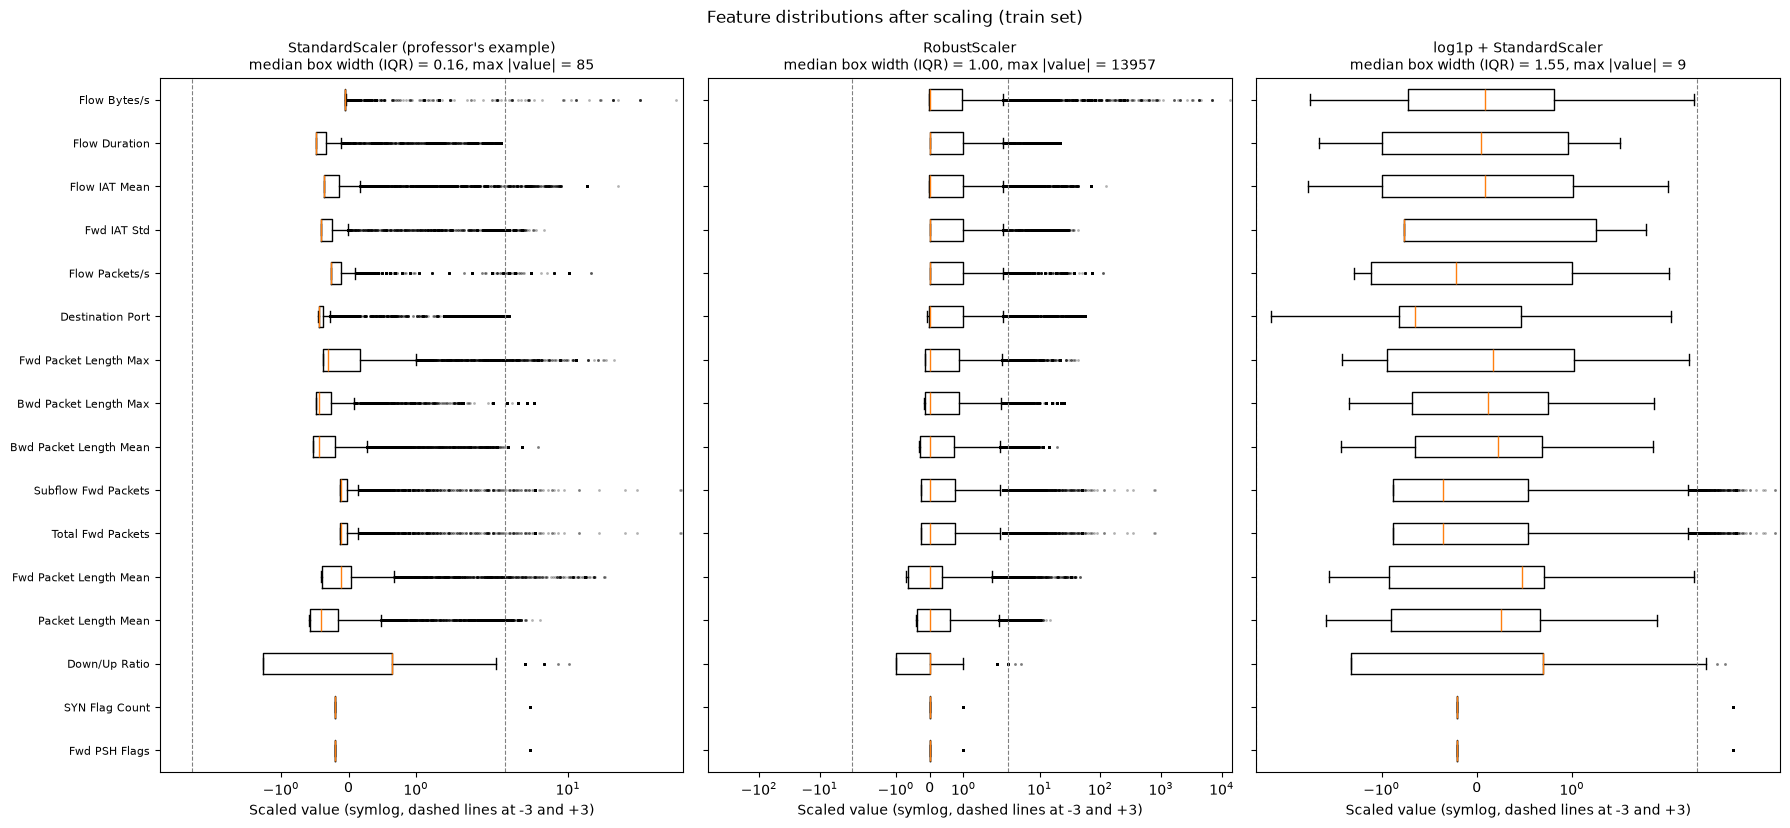

In [222]:
# ------------------------------------------------------------------------------
# SCALING COMPARISON (no training: every option is fitted on the TRAIN set only)
# ------------------------------------------------------------------------------
# After removing negative values all features are >= 0, so log1p can be applied
assert (X_train >= 0).all(), "log1p needs non-negative values"

options = {
    "StandardScaler (professor's example)": StandardScaler().fit_transform(X_train),
    "RobustScaler": RobustScaler().fit_transform(X_train),
    "log1p + StandardScaler": StandardScaler().fit_transform(np.log1p(X_train)),
}
order = pd.DataFrame(X_train, columns=feature_names).max().sort_values().index

fig, axes = plt.subplots(1, 3, figsize=(18, 0.4 * len(order) + 2), sharey=True)
for ax, (name, Z) in zip(axes, options.items()):
    Z_df = pd.DataFrame(Z, columns=feature_names)
    ax.boxplot([Z_df[c] for c in order], orientation="horizontal",
               flierprops=dict(marker=".", markersize=2, alpha=0.3))
    ax.axvline(-3, color="gray", linestyle="--", linewidth=0.8)
    ax.axvline(3, color="gray", linestyle="--", linewidth=0.8)
    ax.set_xscale("symlog")
    ax.set_xlabel("Scaled value (symlog, dashed lines at -3 and +3)")
    box_width = np.median(np.subtract(*np.percentile(Z, [75, 25], axis=0)))   # median IQR over features
    ax.set_title(f"{name}\nmedian box width (IQR) = {box_width:.2f}, max |value| = {np.abs(Z).max():.0f}",
                 fontsize=10)
axes[0].set_yticks(range(1, len(order) + 1))
axes[0].set_yticklabels(order, fontsize=8)
plt.suptitle("Feature distributions after scaling (train set)")
plt.tight_layout()
plt.show()
plt.close()

In [223]:
# ------------------------------------------------------------------------------
# STANDARDIZATION (chosen scaling)
# ------------------------------------------------------------------------------
# "standard" = professor's example, "robust" = RobustScaler, "log_standard" = log1p + StandardScaler
SCALING = "log_standard"   # choice justified with the comparison plot above

X_test_raw = X_test.copy()   # unscaled copy, needed for the Task 3 counterfactual

# log1p has no parameters to learn, so applying it to every partition causes no leakage
if SCALING == "log_standard":
    X_train, X_val, X_test = np.log1p(X_train), np.log1p(X_val), np.log1p(X_test)

# Fit ONLY on the training set, then apply to validation and test
scaler = RobustScaler() if SCALING == "robust" else StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# TASK 2

In [224]:
# ------------------------------------------------------------------------------
# TASK 2
# ------------------------------------------------------------------------------

# ===== CELLA 2: tensori, dataset, dataloader =====
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_val_tensor   = torch.tensor(X_val,   dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val,   dtype=torch.long)
X_test_tensor  = torch.tensor(X_test,  dtype=torch.float32)   # creato ma NON usato in 2A
y_test_tensor  = torch.tensor(y_test,  dtype=torch.long)

BATCH_SIZE = 64
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset   = TensorDataset(X_val_tensor,   y_val_tensor)

g = torch.Generator().manual_seed(SEED)                      # shuffle riproducibile
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)

class_names = list(label_encoder.classes_)
n_features, n_classes = X_train.shape[1], len(class_names)
print(n_features, "feature,", n_classes, "classi")
print("Train:", np.bincount(y_train), "| Val:", np.bincount(y_val))

16 feature, 4 classi
Train: [13467   999  2708  3394] | Val: [2886  214  580  728]


In [225]:
# ===== CELLA 3: modello (1 hidden layer) =====
class SimpleFFNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SimpleFFNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.fc2(x)          # logit grezzi: la softmax e' dentro CrossEntropyLoss
        return x

In [226]:
# ===== CELLA 4: training loop (struttura del professore) =====
def training_loop(model, train_loader, val_loader, train_dataset, val_dataset,
                  device, optimizer, criterion, num_epochs=100,
                  min_delta=None, patience=None):
    """
    Allena il modello, traccia train/val loss e macro-F1 di validation per epoca,
    applica early stopping sulla val loss e ripristina i pesi della best epoch.
    Ritorna un dizionario con le curve, la best epoch e il tempo.
    """
    start_time = time.time()
    train_losses, val_losses, val_f1s = [], [], []
    best_val_loss = float('inf')
    best_epoch = 0
    trigger_times = 0
    best_model_state = None

    for epoch in range(num_epochs):
        # ---- Train ----
        train_loss = 0
        model.train()
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * batch_X.size(0)
        train_loss /= len(train_dataset)
        train_losses.append(train_loss)

        # ---- Validation ----
        val_loss = 0
        preds, labs = [], []
        model.eval()
        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                batch_X, batch_y = batch_X.to(device), batch_y.to(device)
                val_outputs = model(batch_X)
                loss = criterion(val_outputs, batch_y)
                val_loss += loss.item() * batch_X.size(0)
                preds.append(val_outputs.argmax(1).cpu().numpy())
                labs.append(batch_y.cpu().numpy())
        val_loss /= len(val_dataset)
        val_losses.append(val_loss)
        val_f1s.append(f1_score(np.concatenate(labs), np.concatenate(preds),
                                average="macro", zero_division=0))

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, '
                  f'Val Loss: {val_loss:.4f}, Val macro-F1: {val_f1s[-1]:.4f}')

        # ---- Early stopping (sulla val loss) ----
        if min_delta is not None:
            if val_loss < best_val_loss - min_delta:
                best_val_loss = val_loss
                best_epoch = epoch
                best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                trigger_times = 0
            else:
                trigger_times += 1
                if trigger_times >= patience:
                    print(f"Early stopping at epoch {epoch+1} "
                          f"(best epoch {best_epoch+1}, best val loss: {best_val_loss:.6f})")
                    break

    # ---- Restore best model ----
    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    elapsed_time = time.time() - start_time
    print(f'The function took {elapsed_time:.4f} seconds to execute.')

    # ---- Plot ----
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(train_losses, label='Train Loss')
    ax[0].plot(val_losses, label='Validation Loss')
    ax[0].axvline(best_epoch, ls='--', color='gray', label='Best epoch')
    ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss')
    ax[0].set_title('Training and Validation Loss'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(val_f1s, color='green')
    ax[1].axvline(best_epoch, ls='--', color='gray')
    ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Macro-F1 (val)')
    ax[1].set_title('Validation macro-F1'); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

    return {"train_losses": train_losses, "val_losses": val_losses, "val_f1s": val_f1s,
            "best_epoch": best_epoch, "n_epochs": len(train_losses), "time_s": elapsed_time}


def predict(model, dataloader, device):
    """Ritorna (etichette vere, predizioni) su un dataloader."""
    model.eval()
    all_labels, all_predictions = [], []
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            all_labels.extend(labels.numpy())
            all_predictions.extend(predicted.cpu().numpy())
    return np.array(all_labels), np.array(all_predictions)

In [ ]:
# ===== CELLA 5: RUN 2A =====
import pickle
from sklearn.metrics import f1_score

# Define the execution device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Scelte dichiarate: 1 hidden layer x 64, ReLU, CrossEntropy (senza pesi), AdamW lr=5e-4,
# batch 64, max 100 epoche, early stopping su val loss (patience=10, min_delta=1e-5), seed 42
torch.manual_seed(SEED)                                  # stessa init dei pesi a ogni run
model = SimpleFFNN(n_features, 64, n_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4)

min_delta = 1e-5
patience = 10

hist_2A = training_loop(model, train_loader, val_loader, train_dataset, val_dataset,
                        device, optimizer, criterion, num_epochs=100,
                        min_delta=min_delta, patience=patience)

torch.save(model.state_dict(), "baseline_2A.pt")         # servono in 2C e Task 3
pickle.dump(hist_2A, open("hist_2A.pkl", "wb"))

Using device: cuda
Epoch 1/100, Train Loss: 0.6423, Val Loss: 0.3519, Val macro-F1: 0.8801


In [ ]:
# ===== CELLA 6: report di VALIDATION (richiesto dal lab) =====
from sklearn.metrics import classification_report, confusion_matrix

v_true, v_pred = predict(model, val_loader, device)
print(classification_report(v_true, v_pred, target_names=class_names, digits=3))
print("Matrice di confusione (righe = vere, colonne = predette):")
print(confusion_matrix(v_true, v_pred))
print(f"\nBest epoch: {hist_2A['best_epoch']+1} | epoche eseguite: {hist_2A['n_epochs']} "
      f"| tempo: {hist_2A['time_s']:.1f} s")

              precision    recall  f1-score   support

      Benign      0.999     0.989     0.994      2886
 Brute Force      0.914     0.995     0.953       214
    DoS Hulk      0.976     0.997     0.986       580
    PortScan      0.999     0.996     0.997       728

    accuracy                          0.991      4408
   macro avg      0.972     0.994     0.983      4408
weighted avg      0.992     0.991     0.991      4408

Matrice di confusione (righe = vere, colonne = predette):
[[2854   20   11    1]
 [   1  213    0    0]
 [   2    0  578    0]
 [   0    0    3  725]]

Best epoch: 98 | epoche eseguite: 100 | tempo: 120.4 s
